In [1]:
import pathlib 
import numpy as np
import scipy as sp
from matplotlib import pyplot as plt

import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

%load_ext autoreload
%autoreload 2

%matplotlib inline

In [18]:
session_info = {'date': "10_09_2026",
                'genotype_dir': 'R60D05Gal4_iGABASnFR2_R18B05LexA_CsChrimsontdT/exp',
                'fly': 'fly2',
                'session': '2loc_flash-003',
                'full_genotype': '',
                'ecl date': 'ecl: 8/26',
                'fictrac_scan_num': 1,
                'fictrac_dat_file' : 'fictrac-20260910_125331.dat',
                'notes':''}


session_info['fictrac_dir']= f"/media/mplitt/SSD_storage/fictrac_folder/{session_info['genotype_dir']}/{session_info['date']}/{session_info['fly']}"
bruker_folder = pathlib.PurePath('/media/mplitt/SSD_storage/2PData')
# pkl_path = pathlib.PurePath(f"/media/mplitt/SSD_storage/fictrac_folder/{session_info['genotype_dir']}/{session_info['date']}/{session_info['fly']}/fly3_1_scan1.pkl")

pp = st2p.preprocessing.EBImagingSession(session_info = session_info, 
                                         bruker_base_dir = bruker_folder,
                                         fictrac_dir = session_info['fictrac_dir'],
                                         fictrac_dat_file = session_info['fictrac_dat_file'],
                                         fictrac_scan_num = session_info['fictrac_scan_num'],
                                        #  fictrac_pkl_path=pkl_path,
                                        )



In [19]:
if True:
    gd = session_info['genotype_dir']
    d = session_info['date']
    f = session_info['fly']
    s = session_info['session']
    outdir = pathlib.PurePath(f'/media/mplitt/SSD_storage/2P_scratch/{gd}/{d}/{f}/{s}/preprocess.pkl')
    pp = st2p.preprocessing.EBImagingSession.from_file(outdir)
    # # y_r4d = pp.timeseries['rois_R4d_z']
    # y = pp.timeseries['rois_z']
    # n_rois=y.shape[1]

In [4]:
pp.extract_metadata()
pp.align_voltage_recording()


In [4]:
pp.align_fictrac()

FileNotFoundError: [Errno 2] No such file or directory: '/media/mplitt/SSD_storage/fictrac_folder/R60D05Gal4_iGABASnFR2_R18B05LexA_CsChrimsontdT/exp/10_09_2026/fly2/fly2_scan1.pkl'

TypeError: 'NoneType' object is not subscriptable

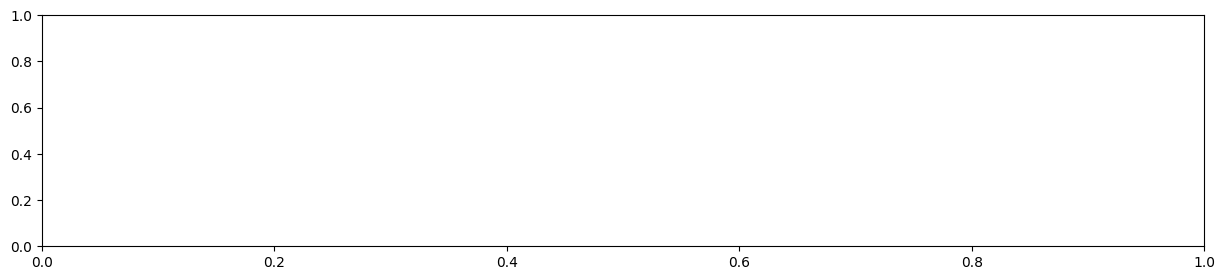

In [5]:
fig, ax = plt.subplots(figsize=[15,3])
time = pp.fictrac_aligned['Time(ms)']
inds = slice(0,100000)
ax.plot(time[inds],pp.fictrac_aligned['integ heading (lab)'].iloc[inds])
ax.plot(time[inds], pp.voltage_recording_aligned[' Heading'].iloc[inds])
ax.plot(time[inds], pp.voltage_recording_aligned[' Y/Index'].iloc[inds])
ax.plot(time[inds], pp.voltage_recording_aligned[' Arena DAC1'].iloc[inds])

In [6]:
pp.bruker_to_h5(first_chan=1, overwrite=True)
data_corr, shifts, error, diffphase= pp.motion_correct(pp.data)

num_cycles > 1, assuming z stacks
sample (237, 265)
(2, 1696, 6, 237, 265)
[########################################] | 100% Completed | 92.60 s
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)
(2,)


In [ ]:
# pp.napari_pickle_noviewer("/home/mplitt/tmp_napari.pkl")

In [ ]:
# import cloudpickle
# filename = "/home/mplitt/tmp_napari.pkl"
# with open(filename, 'rb') as file:
#     napari_layers = cloudpickle.load(file) 


# labels = ['inner_ring', 'outer_ring', 'background', 'rois']
# for k, v in napari_layers.items():
#     if k in labels:
#         pp.napari_labels_layers[k] = v
#     else:
#         pp.napari_layers[k] = v
# n_rois = 16

In [7]:
nap = pp.open_napari()

In [8]:
n_rois = 16
nap.make_phase_masks(n_rois=n_rois)
pp.get_layers(nap)

In [9]:
pp.extract_timeseries(max_proj=False)
# outer_ring = pp.calculate_zscored_F('outer_ring', zscore=True, exp_detrend = True)

In [10]:
pp.save()

In [20]:
frame_times = np.array(pp.metadata['frame_times']).mean(axis=1)
dt = np.diff(frame_times).mean()
heading = np.angle(np.exp(1j*(-1* pp.voltage_recording_aligned[' Heading'].to_numpy()-np.pi)))
index = pp.voltage_recording_aligned[' Y/Index'].to_numpy()
index_bool = index<5
stim_ons = index_bool[1:] & ~index_bool[:-1]
sim_on_inds = np.where(stim_ons)[0]

loc1_inds = sim_on_inds[0::2]
loc2_inds = sim_on_inds[1::2]


background = np.squeeze(pp.timeseries['background'][-1,:,:])
print(background.shape)
background -= background[:20].mean()
print(background.shape)
outer_ring = np.squeeze(pp.timeseries['outer_ring'][-1,:,:]) #- .5*background
# outer_ring = np.squeeze(outer_ring[-1,:,:])


(3551,)
(3551,)


In [21]:
dt

np.float64(0.11042644199999999)

Text(0.5, 1.0, 'background')

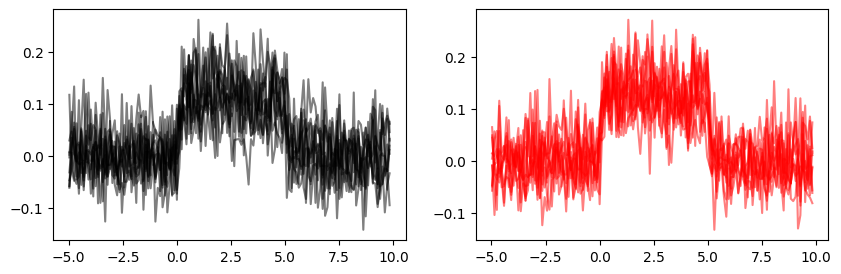

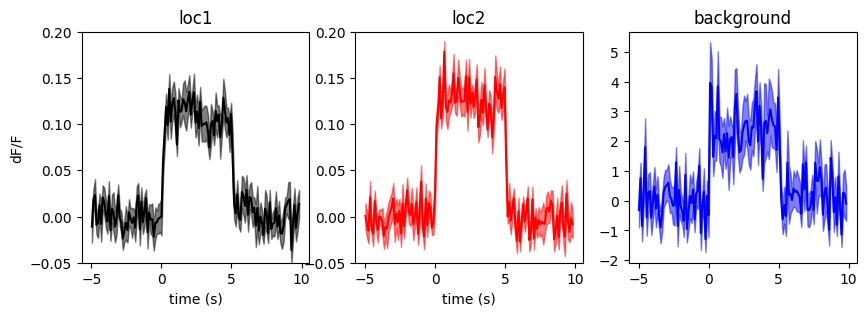

In [22]:
fig, ax = plt.subplots(1,2, figsize=[10,3])
t_before = 5
t_after = 10

inds_before = int(t_before/dt)
inds_after = int(t_after/dt)

loc1_resp = np.zeros((len(loc1_inds), inds_before+inds_after))
loc2_resp = np.zeros((len(loc2_inds), inds_before+inds_after))
background_resp = np.zeros((len(loc1_inds) + len(loc2_inds), inds_before+inds_after))
for row, loc1_ind in enumerate(loc1_inds):

    _resp = outer_ring[loc1_ind-inds_before:loc1_ind+inds_after]
    baseline = _resp[:inds_before].mean()

    _t = np.arange(-inds_before, inds_after)*dt
    loc1_resp[row, :] = _resp/baseline-1
    ax[0].plot(_t, _resp/baseline-1, color='k', alpha=0.5)

    _background = background[loc1_ind-inds_before:loc1_ind+inds_after]
    baseline = _background[:inds_before].mean()
    background_resp[row, :] = _background/baseline-1    
    
for row, loc2_ind in enumerate(loc2_inds):

    _resp = outer_ring[loc2_ind-inds_before:loc2_ind+inds_after]
    baseline = _resp[:inds_before].mean()

    _t = np.arange(-inds_before, inds_after)*dt
    loc2_resp[row, :] = _resp/baseline-1
    ax[1].plot(_t, _resp/baseline-1, color='r', alpha=0.5)

    _background = background[loc2_ind-inds_before:loc2_ind+inds_after]
    baseline = _background[:inds_before].mean()
    background_resp[len(loc1_inds)+row, :] = _background/baseline-1

fig, ax= plt.subplots(1,3, figsize=[10,3])
mu, sem = loc1_resp.mean(axis=0), sp.stats.sem(loc1_resp, axis=0)
ax[0].plot(_t, mu, color='k')
ax[0].fill_between(_t, mu-sem, mu+sem, color='k', alpha=0.5)
ax[0].set_title('loc1')
ax[0].set_xlabel('time (s)')
ax[0].set_ylabel('dF/F')
ax[0].set_ylim([-0.05, .2])
# ax[]

mu, sem = loc2_resp.mean(axis=0), sp.stats.sem(loc2_resp, axis=0)
ax[1].plot(_t, mu, color='r')
ax[1].fill_between(_t, mu-sem, mu+sem, color='r', alpha=0.5)
ax[1].set_title('loc2')
ax[1].set_xlabel('time (s)')
# ax[1].set_ylabel('dF/F')
ax[1].set_ylim([-0.05, .2])

mu, sem = background_resp.mean(axis=0), sp.stats.sem(background_resp, axis=0)
ax[2].plot(_t, mu, color='b')
ax[2].fill_between(_t, mu-sem, mu+sem, color='b', alpha=0.5)
ax[2].set_title('background')

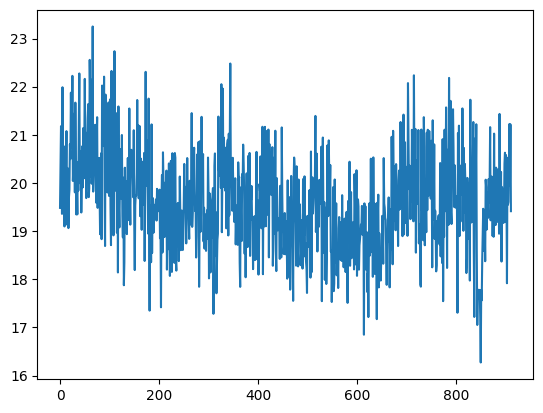

In [23]:
fig,ax = plt.subplots()
ax.plot(outer_ring[index_bool])

# fig, ax = plt.subplots()
# ax.plot(index)

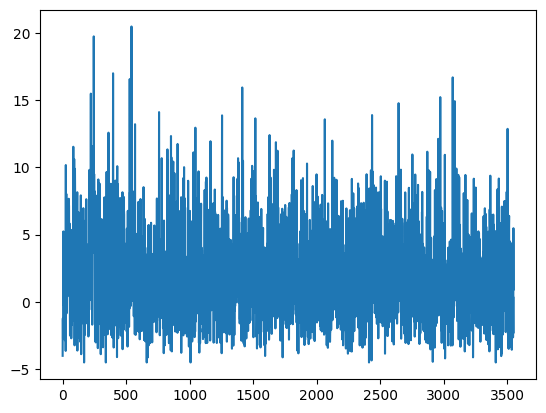

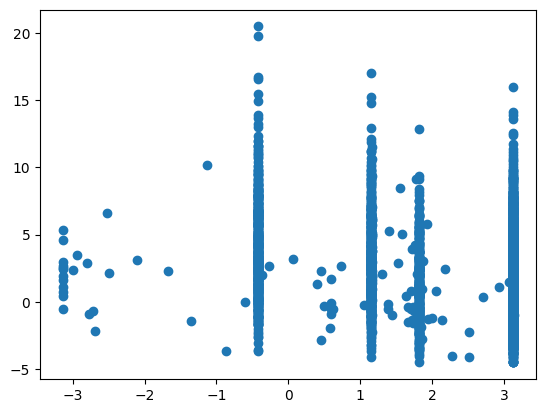

In [24]:
fig, ax= plt.subplots()
ax.plot(pp.timeseries['background'][-1,0,:])
fig, ax= plt.subplots()
ax.scatter(heading, pp.timeseries['background'][-1,0,:])

NameError: name 'y_sm' is not defined

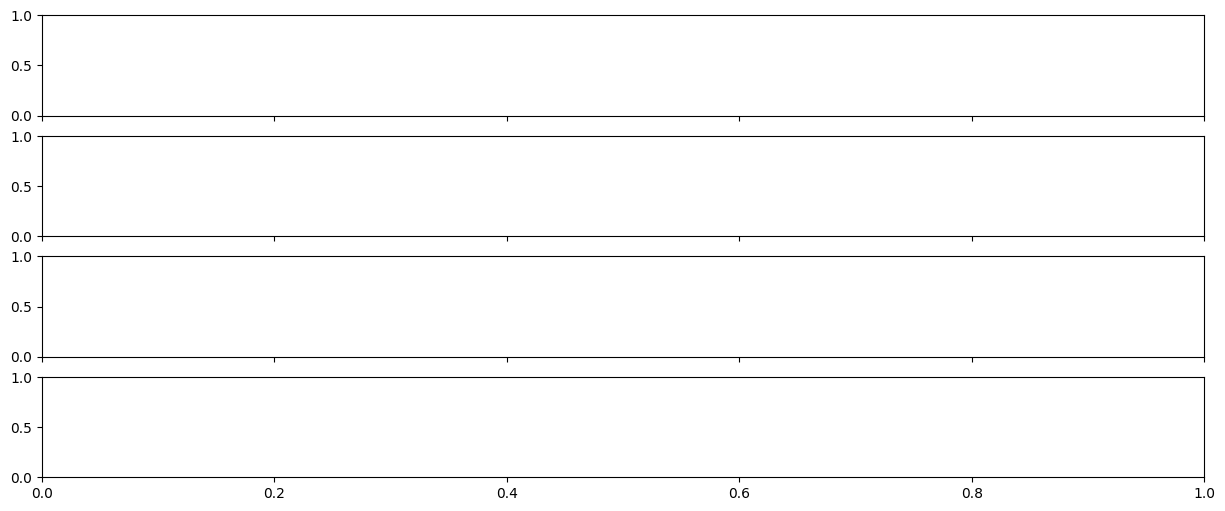

In [ ]:
fig, ax= plt.subplots(4,1, figsize=[15,6], sharex=True)
ax[0].imshow(y_sm[-1,::-1,:]-y_sm[-1,::-1,:].mean(axis=0,keepdims=True), aspect='auto', cmap= 'Blues') #, vmin=-.5,vmax=.5)#, vmin=-1,vmax=1)
ax[1].imshow(y_sm[-1,::-1,:], aspect='auto', cmap= 'Blues', vmin=-.5,vmax=1.5)#, vmin=-1,vmax=1)

ax[0].set_xlabel('EB Wedge')


# print(pp.voltage_recording_aligned.columns)
# fig, ax= plt.subplots()

x = np.arange(y.shape[-1])
# print(y.shape, heading.shape)
ax[2].scatter(x[:]-x[0],heading[:], s=2)
ax[2].scatter(x[:]-x[0], phi[:], s=2)
ax[2].set_ylabel('EB phase')
ax[3].scatter(x[:]-x[0], offset[:])
ax[3].set_ylabel('Offset')

dh = np.angle(np.exp(1j*np.ediff1d(pp.voltage_recording_aligned[' Heading'].to_numpy(), to_end=0)))
# mask = np.abs(dh) >0 #.1

fig, ax= plt.subplots(1,2)
ax[0].hist(dh)
ax[1].hist(offset)
ax[1].set_title(sp.stats.circvar(offset))

Text(0.5, 1.0, '0.9076746483116844')

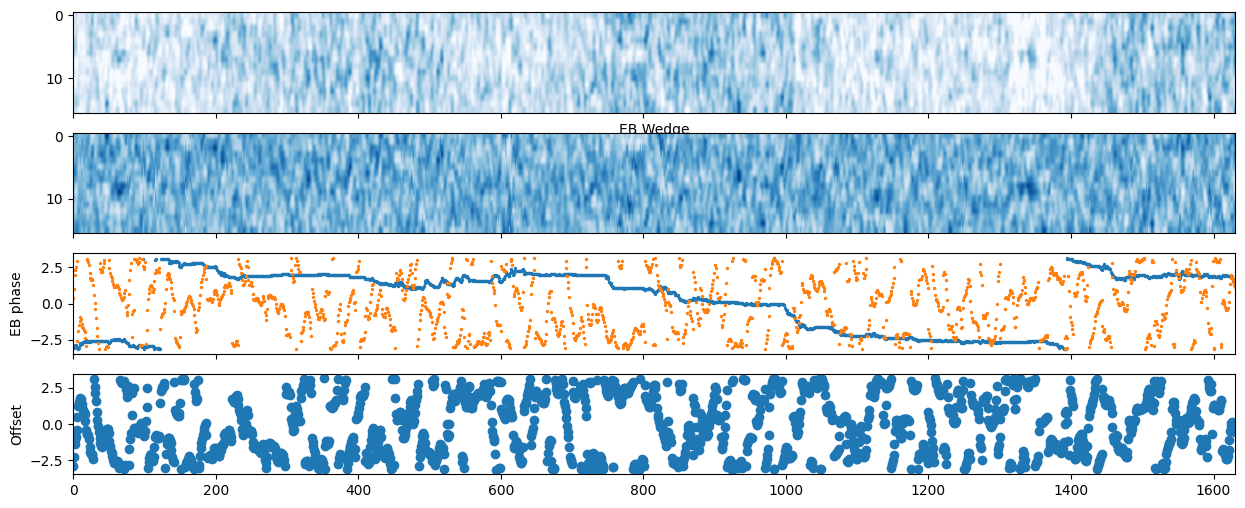

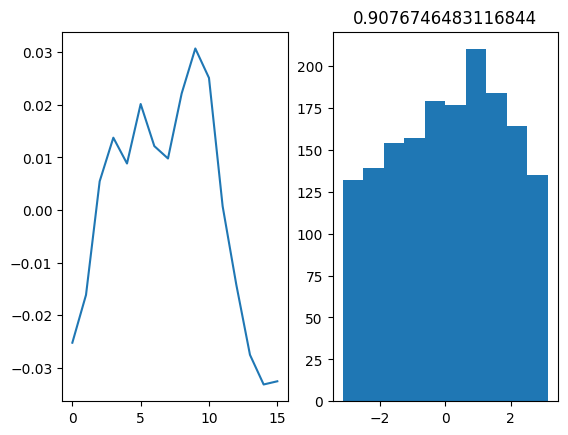

In [ ]:
fig, ax= plt.subplots(4,1, figsize=[15,6], sharex=True)
ax[0].imshow(y_sm[-1,::-1,:], aspect='auto', cmap= 'Blues', vmin=-.5,vmax=1.5)#, vmin=-1,vmax=1)
heading_dig = np.digitize(heading, np.linspace(-np.pi,np.pi,num=16))
y_sm_aligned = np.zeros_like(y_sm)
for t in range(y_sm.shape[-1]):
    y_sm_aligned[:,:,t] = np.roll(y_sm_dm[:,:,t], -heading_dig[t], axis=1)
ax[1].imshow(y_sm_aligned[-1,::-1,:], aspect='auto', cmap= 'Blues')#, vmin=-1,vmax=1)

ax[0].set_xlabel('EB Wedge')


# print(pp.voltage_recording_aligned.columns)
# fig, ax= plt.subplots()

x = np.arange(y.shape[-1])
# print(y.shape, heading.shape)
ax[2].scatter(x[:]-x[0],heading[:], s=2)
ax[2].scatter(x[:]-x[0], phi[:], s=2)
ax[2].set_ylabel('EB phase')
ax[3].scatter(x[:]-x[0], offset[:])
ax[3].set_ylabel('Offset')


x_f,y_f = st2p.utilities.pol2cart(-y_sm_dm[-1,:,:],np.linspace(-np.pi,np.pi,num=n_rois)[:,np.newaxis])
# x_f,y_f = st2p.utilities.pol2cart(y_sm_dm[-1,:,:],np.linspace(-np.pi,np.pi,num=n_rois)[:,np.newaxis])
rho,phi = st2p.utilities.cart2pol(x_f.mean(axis=0), y_f.mean(axis=0))

_,offset = st2p.utilities.cart2pol(*st2p.utilities.pol2cart(np.ones(heading.shape),phi-heading))

fig, ax= plt.subplots(1,2)

mask = (np.abs(heading)<2.5) * (pp.voltage_recording_aligned[' Arena DAC2']<8)
ax[0].plot(y_sm_aligned[-1,::-1,:][:,mask].mean(axis=-1))
ax[1].hist(offset)
ax[1].set_title(sp.stats.circvar(offset))